# 06 · Data augmentation

This notebook compares a baseline CNN, a CNN with dropout, and a CNN with both dropout and random image augmentation. It tracks validation curves and test metrics for each run.


In [1]:
import matplotlib.pyplot as plt

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.models import create_cnn
from src.augmentation import create_augmentation
from src.training import compile_model, create_early_stopping, fit_and_evaluate


I0000 00:00:1790113051.671193  120057 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790113051.742374  120057 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790113053.878609  120057 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Prepare the data

Load and normalize the images. Random transformations are applied by the augmented model during training.


In [2]:
X_train, y_train, writers_train, X_test, y_test, writers_test = load_emnist()

X_train = preprocess_images(X_train)
X_test = preprocess_images(X_test)

## Set up model variants

Early stopping monitors validation loss and restores the best weights. The model list keeps the baseline, dropout, and augmentation comparisons together.


In [3]:
early_stopping = create_early_stopping(patience=2)


In [4]:
models = {
    "Baseline": create_cnn(dropout_rate=0.0),
    "Dropout": create_cnn(dropout_rate=0.5),
    "Dropout + Augmentation": create_cnn(
        dropout_rate=0.5,
        augmentation=create_augmentation(),
    ),
}


W0000 00:00:1790113056.978128  120057 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [5]:
for model in models.values():
    compile_model(model, learning_rate=0.001)


## Train and compare

The same training settings are used for all variants. Review the learning curves as well as test accuracy and loss.


In [6]:
results = {}

for name, model in models.items():
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    result = fit_and_evaluate(
        model, X_train, y_train, X_test, y_test,
        epochs=15, batch_size=128, callbacks=[early_stopping], verbose=1,
    )
    results[name] = result
    print(f"Test accuracy: {result['test_accuracy']:.4f}")
    print(f"Test loss: {result['test_loss']:.4f}")



==================== Baseline ====================
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 44s 25ms/step - accuracy: 0.9756 - loss: 0.0834 - val_accuracy: 0.9910 - val_loss: 0.0315
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 40s 24ms/step - accuracy: 0.9921 - loss: 0.0270 - val_accuracy: 0.9916 - val_loss: 0.0289
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 39s 23ms/step - accuracy: 0.9943 - loss: 0.0193 - val_accuracy: 0.9928 - val_loss: 0.0242
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 39s 23ms/step - accuracy: 0.9956 - loss: 0.0148 - val_accuracy: 0.9941 - val_loss: 0.0211
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 41s 23ms/step - accuracy: 0.9965 - loss: 0.0120 - val_accuracy: 0.9934 - val_loss: 0.0236
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 40s 24ms/step - accuracy: 0.9974 - loss: 0.0093 - val_accuracy: 0.9933 - val_loss: 0.0228
Test accuracy: 0.9947
Test loss: 0.0186

==================== Dropout ====================
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 40s 23ms/step - accurac

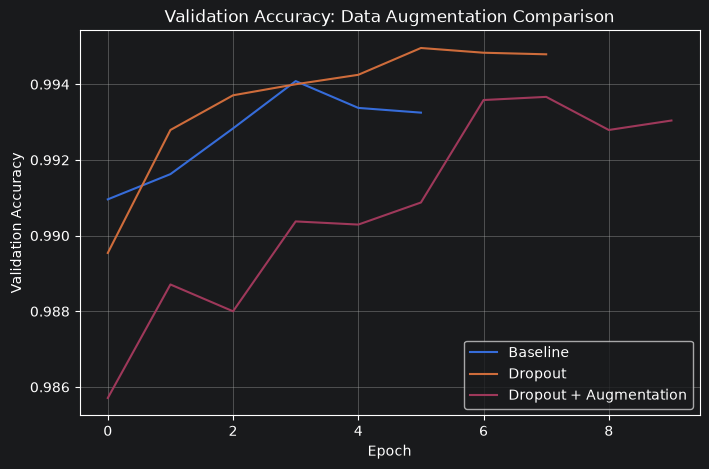

In [7]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    history = result["history"]
    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy: Data Augmentation Comparison")
plt.legend()
plt.grid(True)
plt.show()

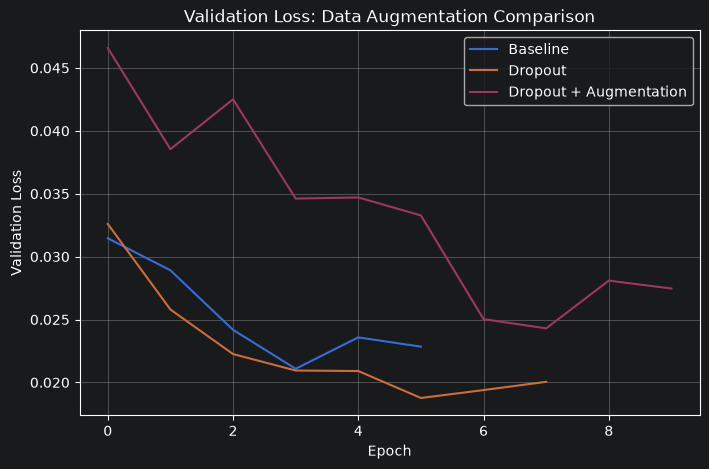

In [8]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    history = result["history"]
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss: Data Augmentation Comparison")
plt.legend()
plt.grid(True)
plt.show()

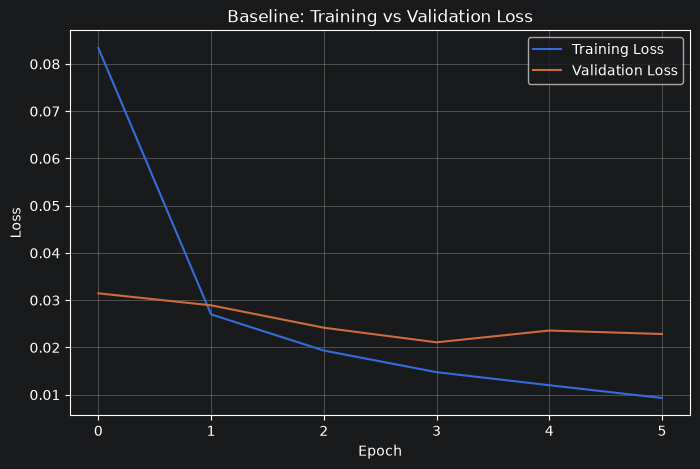

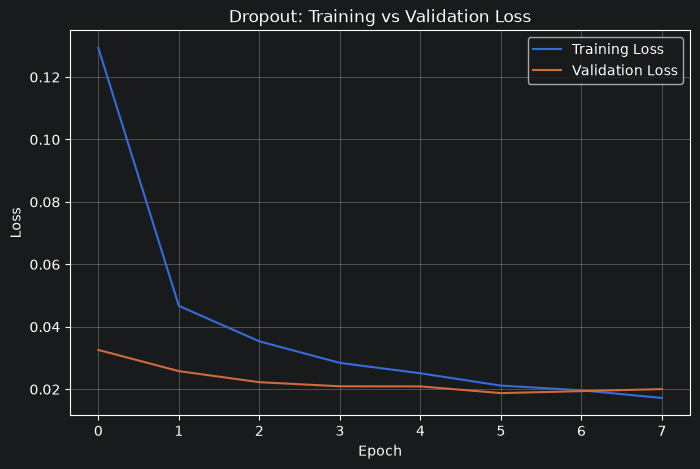

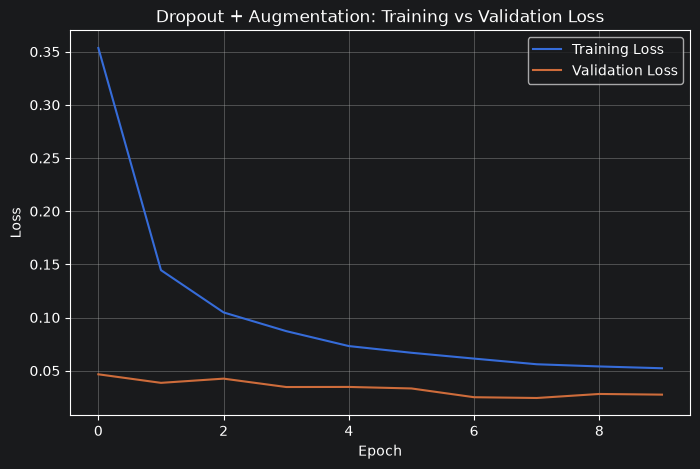

In [9]:
for name, result in results.items():
    history = result["history"]

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{name}: Training vs Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

## Visualize test metrics

The bar charts make small differences in test accuracy and loss easier to compare.


In [10]:
for name, result in results.items():
    print(
        f"{name}: "
        f"accuracy = {result['test_accuracy']:.4f}, "
        f"loss = {result['test_loss']:.4f}"
    )

Baseline: accuracy = 0.9947, loss = 0.0186
Dropout: accuracy = 0.9956, loss = 0.0159
Dropout + Augmentation: accuracy = 0.9942, loss = 0.0205


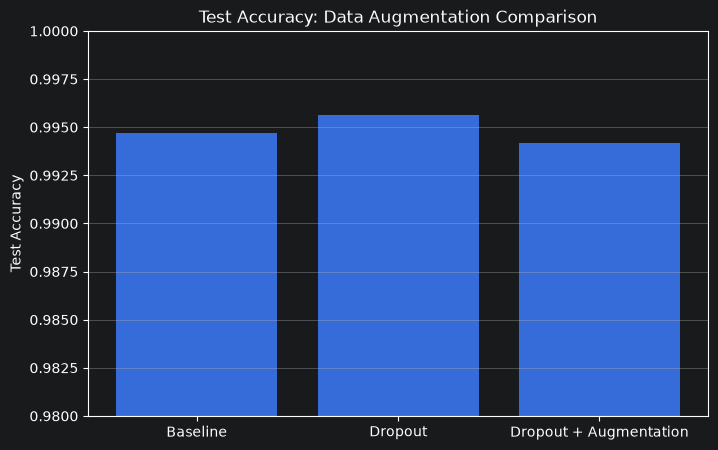

In [11]:
accuracy = {
    name: result["test_accuracy"]
    for name, result in results.items()
}

plt.figure(figsize=(8, 5))
plt.bar(accuracy.keys(), accuracy.values())

plt.ylabel("Test Accuracy")
plt.title("Test Accuracy: Data Augmentation Comparison")
plt.ylim(0.98, 1.0)
plt.grid(axis="y")

plt.show()

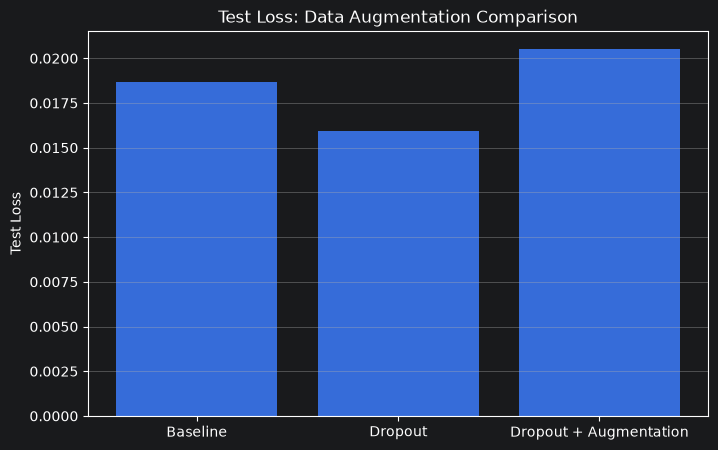

In [12]:
loss = {
    name: result["test_loss"]
    for name, result in results.items()
}

plt.figure(figsize=(8, 5))
plt.bar(loss.keys(), loss.values())

plt.ylabel("Test Loss")
plt.title("Test Loss: Data Augmentation Comparison")

plt.grid(axis="y")

plt.show()

## Save the summary

The final cell saves the metrics and number of completed epochs in the project’s `models` folder.


In [13]:
import json

summary = {
    name: {
        "test_accuracy": float(result["test_accuracy"]),
        "test_loss": float(result["test_loss"]),
        "epochs": len(result["history"].history["loss"])
    }
    for name, result in results.items()
}

with open("../models/augmentation_results.json", "w") as f:
    json.dump(summary, f, indent=4)

## Results

In the saved run, the baseline reached **99.47%** accuracy (loss **0.0186**), dropout reached **99.56%** (loss **0.0159**), and dropout plus augmentation reached **99.42%** (loss **0.0205**). Dropout alone was highest in this run; augmentation did not improve the measured test result here.
